<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Grafos y recomendación basada en contenido</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Grafo de películas por co-ocurrencia de "me gusta", PageRank global y personalizado por el método de potencias, caminatas aleatorias en el grafo bipartito usuario–película y perfiles de contenido con TF-IDF del título, año y factores latentes.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Recomendar con dos familias de métodos que no factorizan la matriz de ratings:

- **Grafos** (Leskovec *et al.*, *Mining of Massive Datasets*, cap. 5 y 10): construimos un grafo de películas a partir
  de los usuarios que comparten gustos, medimos qué películas son **centrales** con PageRank y recomendamos con
  **PageRank personalizado**: un paseo aleatorio que reinicia en las películas que le gustaron al usuario. Como segunda
  vista usamos el grafo **bipartito** usuario–película.
- **Contenido** (MMDS, sección 9.2; Aggarwal, 2016, cap. 4, como en nuestra exposición de sistemas basados en
  contenido): perfiles de película con **TF-IDF del título** y el **año**, y perfiles de usuario como promedio de las
  películas que le gustaron. El Netflix Prize casi no trae metadatos y reconocemos esa limitación de entrada; por eso
  probamos también los **factores latentes** del notebook 3 como perfil de película (un híbrido).

### Los datos

La submuestra S (`S_R_train.npz`), el catálogo, el baseline y el SVD-SGD de S (`modelos/`), y los usuarios de la
evaluación top-N. Todo es de tamaño S: un grafo de 5,000 películas y 100,000 usuarios.

### Contenido

1. **Datos y protocolo.**
2. **Grafo de películas y PageRank global.**
3. **PageRank personalizado** con el método de potencias.
4. **Caminatas en el grafo bipartito** usuario–película.
5. **Recomendación basada en contenido.**
6. **Resumen.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import psutil
import networkx as nx
import matplotlib.pyplot as plt
from numba import njit, prange
from scipy.linalg.blas import ssyrk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
RUTA_RESULTADOS, RUTA_PREDICCIONES, RUTA_MODELOS = [RUTA_PROCESADOS / c for c in ["resultados", "predicciones", "modelos"]]
SEMILLA = 42

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    return f"{100 * x:,.{dec}f} %"


def tamano(nbytes):
    return f"{nbytes / 1e9:,.2f} GB" if nbytes >= 1e9 else f"{nbytes / 1e6:,.1f} MB"


registro_ram = []


def ram(paso):
    rss, libre = psutil.Process().memory_info().rss, psutil.virtual_memory().available
    registro_ram.append({"paso": paso, "RAM del proceso": tamano(rss), "RAM libre del sistema": tamano(libre)})
    print(f"[RAM] {paso}: proceso {tamano(rss)} | libre en el sistema {tamano(libre)}")


def rmse(pred, real):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - real) ** 2)))


def guardar_resultado(modelo, **metricas):
    with open(RUTA_RESULTADOS / f"{modelo}.json", "w", encoding="utf-8") as f:
        json.dump({"modelo": modelo, **metricas}, f, ensure_ascii=False, indent=1)


ram("inicio")

[RAM] inicio: proceso 235.6 MB | libre en el sistema 7.69 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">GRAFOS · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos y protocolo</span></div>



Usamos el mismo protocolo que los notebooks anteriores: validación tipo probe (el último rating de cada usuario) para
elegir hiperparámetros, con un top-N de validación cuyo relevante es ese último rating si fue 4 o 5, y el top-N de
prueba sobre el probe de S con los mismos 5,000 usuarios.

In [2]:
# S, validación tipo probe, top-N de validación y de prueba
@njit
def ultimo_por_fila(indptr, dias, semilla):
    pos = np.full(len(indptr) - 1, -1, np.int64)
    for u in range(len(indptr) - 1):
        if indptr[u + 1] - indptr[u] < 2:
            continue
        clave_mejor = -1
        for k in range(indptr[u], indptr[u + 1]):
            clave = dias[k] * 4294967296 + (k * 2654435761 + semilla) % 4294967296
            if clave > clave_mejor:
                pos[u], clave_mejor = k, clave
    return pos


def sub_csr(X, conservar):
    filas = np.repeat(np.arange(X.shape[0], dtype=np.int32), np.diff(X.indptr))[conservar]
    indptr = np.zeros(X.shape[0] + 1, dtype=np.int32)
    indptr[1:] = np.cumsum(np.bincount(filas, minlength=X.shape[0]))
    return sp.csr_matrix((X.data[conservar], X.indices[conservar], indptr), shape=X.shape)


S_R = sp.load_npz(RUTA_PROCESADOS / "S_R_train.npz")
n_S_usr, N_PEL = S_R.shape
pos = ultimo_por_fila(S_R.indptr, np.load(RUTA_PROCESADOS / "S_dias.npy"), SEMILLA)
S_val_u = np.flatnonzero(pos >= 0).astype(np.int32)
pos = pos[S_val_u]
S_val_i, S_val_r = S_R.indices[pos], S_R.data[pos]
es_val = np.zeros(S_R.nnz, dtype=bool)
es_val[pos] = True
S_tr = sub_csr(S_R, ~es_val)
S_probe_u, S_probe_m, S_probe_r = [np.load(RUTA_PROCESADOS / f"S_probe_{x}.npy") for x in "umr"]
S_peliculas = np.load(RUTA_PROCESADOS / "S_peliculas.npy")
peliculas = pd.read_parquet(RUTA_PROCESADOS / "peliculas.parquet")
titulo = lambda i: f"{peliculas.loc[S_peliculas[i], 'title']} ({peliculas.loc[S_peliculas[i], 'year']})"
popularidad = np.diff(S_R.tocsc().indptr).astype(np.float32)

K = 10
DESCUENTO = 1 / np.log2(np.arange(2, K + 2))
gusta_probe = S_probe_r >= 4
REL = sp.csr_matrix((np.ones(gusta_probe.sum(), dtype=bool), (S_probe_u[gusta_probe], S_probe_m[gusta_probe])), shape=S_R.shape)
U_EVAL = np.load(RUTA_PROCESADOS / "S_usuarios_topn.npy")
gusta_val = S_val_r >= 4
REL_VAL = sp.csr_matrix((np.ones(gusta_val.sum(), dtype=bool), (S_val_u[gusta_val], S_val_i[gusta_val])), shape=S_R.shape)
U_VAL = np.sort(np.random.default_rng(SEMILLA).choice(S_val_u[gusta_val], 5_000, replace=False)).astype(np.int32)


def evaluar_topn(puntuar, usuarios=U_EVAL, rel=REL, vistos=S_R, lote=500):
    # puntuar(us) devuelve una matriz (usuarios × películas) o un dict {nombre: matriz} para evaluar varios puntajes a la vez
    acum = {}
    for a in range(0, len(usuarios), lote):
        us = usuarios[a:a + lote]
        salida = puntuar(us)
        salidas = salida if isinstance(salida, dict) else {None: salida}
        f, c = vistos[us].nonzero()
        rel_lote = rel[us].toarray()
        n_rel = rel_lote.sum(1)
        for nombre, punt in salidas.items():
            punt = np.array(punt, dtype=np.float32)
            punt[f, c] = -np.inf
            top = np.argpartition(-punt, K, axis=1)[:, :K]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(punt, top, 1), axis=1), 1)
            aciertos = np.take_along_axis(rel_lote, top, 1)
            p, r, n = acum.setdefault(nombre, ([], [], []))
            p.append(aciertos.sum(1) / K)
            r.append(aciertos.sum(1) / n_rel)
            n.append((aciertos * DESCUENTO).sum(1) / np.cumsum(DESCUENTO)[np.minimum(n_rel, K) - 1])
    res = {nombre: {f"P@{K}": float(np.concatenate(p).mean()), f"R@{K}": float(np.concatenate(r).mean()),
                    f"NDCG@{K}": float(np.concatenate(n).mean())} for nombre, (p, r, n) in acum.items()}
    return res[None] if list(res) == [None] else res


def gusta(X):
    G = sp.csr_matrix(((X.data >= 4).astype(np.float32), X.indices.copy(), X.indptr.copy()), shape=X.shape)
    G.eliminate_zeros()  # con copias: eliminate_zeros modifica los arreglos en su lugar
    return G


G_tr, G = gusta(S_tr), gusta(S_R)
referencias = {m: json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8"))
               for m in ["Popularidad", "kNN ítem-ítem (suma de similitudes)", "PureSVD (S)", "Reglas de asociación (S)"]}
print(f"S: {n_S_usr:,} × {N_PEL:,} | \"me gusta\" (rating ≥ 4): {G.nnz:,} ({pct(G.nnz / S_R.nnz)} de los ratings) | "
      f"validación: {len(S_val_r):,} | top-N de validación: {len(U_VAL):,} usuarios")
ram("1. datos")

S: 100,000 × 5,000 | "me gusta" (rating ≥ 4): 11,085,355 (57.34 % de los ratings) | validación: 99,404 | top-N de validación: 5,000 usuarios
[RAM] 1. datos: proceso 948.4 MB | libre en el sistema 6.97 GB


**Observaciones: datos**

- **"Me gusta".** De los 19.3 millones de ratings de S, **11.1 millones** (57.3 %) son de 4 o 5. Los grafos y los
  perfiles de usuario de este notebook se construyen con ellos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">GRAFOS · PAGERANK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Grafo de películas y PageRank global</span></div>



**Construcción del grafo.** Dos películas se parecen si les gustaron a los mismos usuarios. Medimos la similitud con el
coseno de sus columnas en la matriz binaria de "me gusta" $G$:
$c_{ij} = \frac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|}}$, calculado como la matriz de Gram $G^\top G$ por bloques con BLAS.
El grafo completo sería casi denso (5,000 × 5,000), así que cada película $i$ se enlaza solo con sus **$k = 30$ vecinas
más similares**, con arista dirigida $i \to j$ de peso $c_{ij}$. Así ningún nodo queda colgante: todos tienen 30
aristas de salida.

**PageRank** (MMDS, cap. 5). La matriz de transición es $M_{ji} = c_{ij} / \sum_{j'} c_{ij'}$, estocástica por
columnas: un paseante en $i$ salta a una vecina con probabilidad proporcional a la similitud. Con teletransportación,

$$r = \beta M r + (1 - \beta)\, v,$$

con $v$ uniforme y $\beta = 0.85$. Lo resolvemos con el **método de potencias** (implementado por nosotros, como en la
práctica 3): partimos de $r_0 = v$ e iteramos hasta $\lVert r_{t+1} - r_t \rVert_1 < 10^{-10}$. La misma función acepta
una **matriz** de vectores de teletransportación, una columna por usuario, que usaremos en la sección 3.

In [3]:
# Gram de "me gusta" por bloques, grafo de las k vecinas más similares y PageRank por el método de potencias
def gram(X, bloque=8_000):
    C = np.zeros((X.shape[1], X.shape[1]), dtype=np.float32, order="F")
    for a in range(0, X.shape[0], bloque):
        C = ssyrk(1.0, X[a:a + bloque].toarray(), beta=1.0, c=C, trans=1, overwrite_c=1)
    C = np.triu(C)
    return np.ascontiguousarray(C + np.triu(C, 1).T)


def grafo_vecinas(G, k):
    # Matriz W (n × n) con las k vecinas de mayor coseno de cada película, y la matriz de co-ocurrencias
    C = gram(G)
    d = np.sqrt(np.diag(C))
    d[d == 0] = np.inf
    cos = C / d[:, None] / d[None, :]
    np.fill_diagonal(cos, 0)
    vecinas = np.argpartition(-cos, k, axis=1)[:, :k]
    filas = np.repeat(np.arange(cos.shape[0]), k)
    W = sp.csr_matrix((cos[filas, vecinas.ravel()], (filas, vecinas.ravel())), shape=cos.shape)
    return W, C


def transicion(W):
    # M estocástica por columnas: M[j, i] = w_ij / Σ_j w_ij
    salida = np.asarray(W.sum(axis=1)).ravel()
    return (sp.diags(1 / np.where(salida > 0, salida, 1)) @ W).T.tocsr()


def pagerank(M, v, beta=0.85, tol=1e-10, max_iter=1000):
    # Método de potencias: r ← βMr + (1 − β)v; v puede ser un vector o una matriz (una columna por usuario)
    r = v.copy()
    for it in range(1, max_iter + 1):
        nuevo = beta * (M @ r) + (1 - beta) * v
        error = np.abs(nuevo - r).sum(axis=0).max()
        r = nuevo
        if error < tol:
            break
    return r, it


K_VECINAS = 30
t0 = time.perf_counter()
W, C = grafo_vecinas(G, K_VECINAS)
M = transicion(W)
pr_global, iters = pagerank(M, np.full(N_PEL, 1 / N_PEL))
seg_grafo = time.perf_counter() - t0
grado_in = np.diff(W.tocsc().indptr)

grafo = nx.from_scipy_sparse_array(W, create_using=nx.DiGraph)
scc = max(nx.strongly_connected_components(grafo), key=len)
display(pd.Series({
    "Nodos / aristas": f"{N_PEL:,} / {W.nnz:,}",
    "Aristas recíprocas": pct(W.multiply(W.T > 0).nnz / W.nnz, 1),
    "Grado de entrada (mín / mediana / máx)": f"{grado_in.min()} / {np.median(grado_in):.0f} / {grado_in.max()}",
    "Películas que no son vecinas de nadie": f"{(grado_in == 0).sum():,}",
    "Componente fuertemente conexa mayor": f"{len(scc):,} nodos ({pct(len(scc) / N_PEL, 1)})",
    "PageRank: iteraciones / suma": f"{iters} / {pr_global.sum():.6f}",
    "Tiempo (Gram + grafo + PageRank)": f"{seg_grafo:.0f} s",
}, name="Valor").rename_axis("Grafo de películas (k = 30)").to_frame())
ram("2. grafo y PageRank")

,Valor
Grafo de películas (k = 30),
Nodos / aristas,"5,000 / 150,000"
Aristas recíprocas,31.9 %
Grado de entrada (mín / mediana / máx),0 / 20 / 404
Películas que no son vecinas de nadie,83
Componente fuertemente conexa mayor,"4,857 nodos (97.1 %)"
PageRank: iteraciones / suma,92 / 1.000000
Tiempo (Gram + grafo + PageRank),30 s


[RAM] 2. grafo y PageRank: proceso 1.12 GB | libre en el sistema 6.79 GB


,película,PageRank,grado de entrada,lugar por grado de entrada,lugar por popularidad
1,Raiders of the Lost Ark (1981),60.87,366,3,91
2,The Sixth Sense (1999),58.86,372,2,31
3,The Silence of the Lambs (1991),57.35,404,1,77
4,The Matrix (1999),56.95,328,5,46
5,The Shawshank Redemption: Special Edition (1994),55.89,341,4,53
6,Lord of the Rings: The Fellowship of the Ring (2001),55.14,290,6,32
7,Lord of the Rings: The Two Towers (2002),51.45,237,15,27
8,Forrest Gump (1994),50.02,247,12,8
9,Gladiator (2000),50.02,228,18,28
10,Braveheart (1995),49.77,229,17,60


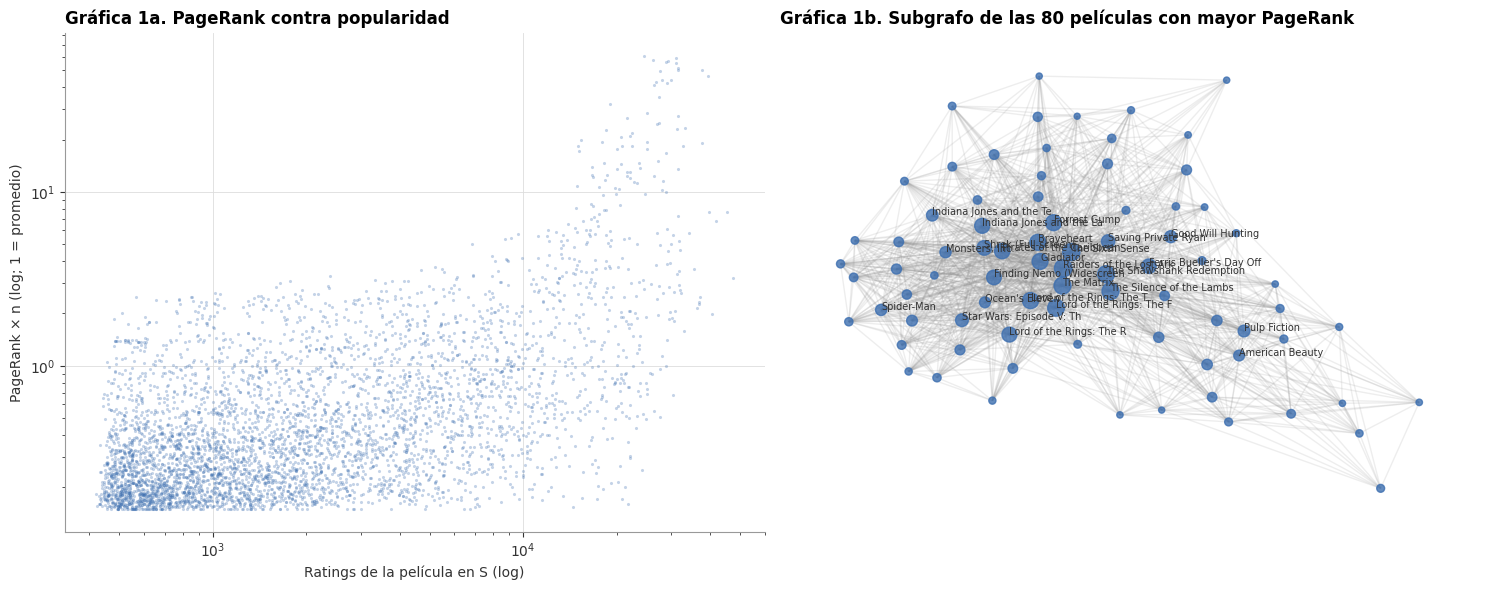

Spearman (PageRank, popularidad) = 0.494 | (PageRank, grado de entrada) = 0.961


In [4]:
# Las películas más centrales según PageRank, comparadas con su lugar por popularidad y por grado de entrada
lugar_pop = pd.Series(popularidad).rank(ascending=False, method="min").astype(int)
lugar_in = pd.Series(grado_in).rank(ascending=False, method="min").astype(int)
top_pr = np.argsort(-pr_global)[:15]
display(pd.DataFrame({"película": [titulo(i) for i in top_pr], "PageRank": (pr_global[top_pr] * N_PEL).round(2),
                      "grado de entrada": grado_in[top_pr], "lugar por grado de entrada": lugar_in[top_pr].to_numpy(),
                      "lugar por popularidad": lugar_pop[top_pr].to_numpy()}, index=range(1, 16)))

from scipy.stats import spearmanr
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.scatter(popularidad, pr_global * N_PEL, s=5, color=AZUL, alpha=0.3, linewidths=0)
ax1.set_xscale("log")
ax1.set_yscale("log")
estilo_ejes(ax1, "Gráfica 1a. PageRank contra popularidad", "Ratings de la película en S (log)",
            "PageRank × n (log; 1 = promedio)", rejilla="both")

# Subgrafo de las 80 películas con mayor PageRank
sub = np.argsort(-pr_global)[:80]
H = nx.Graph()
H.add_nodes_from(range(len(sub)))
Wsub = W[sub][:, sub].tocoo()
H.add_edges_from(zip(Wsub.row, Wsub.col))
posiciones = nx.spring_layout(H, seed=SEMILLA, k=0.35)
nx.draw_networkx_edges(H, posiciones, ax=ax2, alpha=0.15, edge_color=GRIS)
nx.draw_networkx_nodes(H, posiciones, ax=ax2, node_size=pr_global[sub] / pr_global[sub].max() * 160, node_color=AZUL, alpha=0.8)
for j in range(25):
    ax2.annotate(peliculas.loc[S_peliculas[sub[j]], "title"][:24], posiciones[j], fontsize=7, color=TINTA)
ax2.set_axis_off()
ax2.set_title("Gráfica 1b. Subgrafo de las 80 películas con mayor PageRank", loc="left")
plt.tight_layout()
plt.show()
print(f"Spearman (PageRank, popularidad) = {spearmanr(pr_global, popularidad).statistic:.3f} | "
      f"(PageRank, grado de entrada) = {spearmanr(pr_global, grado_in).statistic:.3f}")

**Observaciones: grafo de películas y PageRank global**

- **Estructura.** El grafo tiene 5,000 nodos y 150,000 aristas, y el **31.9 %** de ellas es recíproco: la relación
  de "vecina más parecida" no es simétrica.
  - El grado de entrada va de 0 a **404**, con mediana 20: unas pocas películas son vecinas de cientos de otras.
  - **83** películas no son vecinas de nadie.
  - La componente fuertemente conexa mayor tiene el **97.1 %** de los nodos.
  - El método de potencias converge en **92 iteraciones**. Todo (Gram, grafo y PageRank) tarda 30 s.
- **Las más centrales no son las más populares.** Encabezan *Raiders of the Lost Ark*, *The Sixth Sense*, *The Silence
  of the Lambs*, *The Matrix* y *The Shawshank Redemption*, que ocupan los lugares 91, 31, 77, 46 y 53 por número de
  ratings. La correlación de rangos entre PageRank y popularidad es apenas **0.49** (Gráfica 1a). En cambio, con el
  grado de entrada es **0.96**: es central quien aparece como vecina de muchas.
- **Interpretación.** PageRank premia a las películas **"puente"**: clásicos que le gustan a públicos muy distintos y
  por eso resultan parecidos a muchas películas de géneros variados. *Miss Congeniality*, la más calificada, no está
  en el top: su público es grande pero homogéneo.
- **Como recomendador no personalizado** (P@10 = 0.0055, NDCG@10 = 0.0149) es casi igual a la popularidad.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">GRAFOS · PERSONALIZADO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PageRank personalizado</span></div>



**Idea.** En lugar de teletransportarse a cualquier película, el paseante reinicia en las películas que le gustaron al
usuario: $v_u$ es uniforme sobre ellas (MMDS, sección 5.3, *topic-sensitive PageRank*). El vector estacionario $r_u$
mide qué tan cerca, en el grafo, está cada película de los gustos de $u$. Es un **paseo aleatorio con reinicio**, que
calculamos con el mismo método de potencias para 1,000 usuarios a la vez (una matriz $5{,}000 \times 1{,}000$).

**Dos puntajes.**

- **$r_u$ directo.** Favorece a las películas centrales, que están cerca de todo.
- **Especificidad** $r_u \ln(r_u / r)$, la señal de nuestra práctica 3 (recomendaciones de Wikipedia): premia lo que el
  paseo de $u$ visita **más que el paseo global**.

Elegimos $\beta \in \{0.2, 0.35, 0.5, 0.7, 0.85\}$ con el top-N de validación, sobre un grafo construido sin la validación. Para que
1,000 paseos simultáneos sean rápidos, $M$ se guarda densa en `float32` (100 MB) y cada iteración es un producto
matriz-matriz con BLAS. Como solo importa el orden, paramos con tolerancia $10^{-6}$.

In [5]:
# β por top-N de validación (grafo sin la validación) y PageRank personalizado en el probe
def teleport(Gm, us):
    V = Gm[us].toarray().T.astype(np.float32)
    vacios = V.sum(axis=0) == 0
    V[:, vacios] = 1.0  # usuarios sin "me gusta": teletransportación uniforme
    return V / V.sum(axis=0)


def puntuar_ppr(M_densa, Gm, beta, pr_ref):
    # Un método de potencias por lote (M densa en float32 para usar BLAS); devuelve los dos puntajes
    def puntuar(us):
        r, _ = pagerank(M_densa, teleport(Gm, us), beta=beta, tol=1e-6)
        r = r.T
        return {"r_u directo": r, "especificidad": r * np.log(np.maximum(r, 1e-30) / pr_ref)}
    return puntuar


W_tr, _ = grafo_vecinas(G_tr, K_VECINAS)
M_tr = transicion(W_tr)
pr_tr, _ = pagerank(M_tr, np.full(N_PEL, 1 / N_PEL))
M_tr_densa = M_tr.toarray().astype(np.float32)
t0 = time.perf_counter()
validacion_ppr = []
for beta in [0.2, 0.35, 0.5, 0.7, 0.85]:
    for puntaje, m in evaluar_topn(puntuar_ppr(M_tr_densa, G_tr, beta, pr_tr), U_VAL, REL_VAL, S_tr, lote=1000).items():
        validacion_ppr.append({"β": beta, "puntaje": puntaje, **m})
validacion_ppr = pd.DataFrame(validacion_ppr)
print(f"Validación de β (5 valores × 5,000 usuarios): {time.perf_counter() - t0:.0f} s")
display(validacion_ppr.pivot(index="puntaje", columns="β", values=f"NDCG@{K}").round(4))
mejor = validacion_ppr.loc[validacion_ppr.groupby("puntaje")[f"NDCG@{K}"].idxmax()].set_index("puntaje")
del W_tr, M_tr, M_tr_densa
gc.collect()

M_densa = M.toarray().astype(np.float32)
t0 = time.perf_counter()
topn_ppr = {}
for beta in sorted(set(mejor["β"])):
    res = evaluar_topn(puntuar_ppr(M_densa, G, beta, pr_global), lote=1000)
    topn_ppr.update({p: res[p] for p in mejor.index if mejor.loc[p, "β"] == beta})
seg_ppr = time.perf_counter() - t0
topn_pr_global = evaluar_topn(lambda us: np.broadcast_to(pr_global, (len(us), N_PEL)))
sp.save_npz(RUTA_MODELOS / "grafo_peliculas_S.npz", W)
np.savez(RUTA_MODELOS / "pagerank_S.npz", pr_global=pr_global, beta_ppr=mejor.loc["r_u directo", "β"],
         beta_esp=mejor.loc["especificidad", "β"])
guardar_resultado("PageRank global (S)", tipo="top-N", escala="S", **topn_pr_global,
                  configuracion=f"grafo de {K_VECINAS} vecinas por coseno de me gusta, β = 0.85")
guardar_resultado("PageRank personalizado (S)", tipo="top-N", escala="S", segundos_topn=seg_ppr,
                  configuracion=f"reinicio en las películas con rating ≥ 4, β = {mejor.loc['r_u directo', 'β']}",
                  **topn_ppr["r_u directo"])
guardar_resultado("PageRank personalizado, especificidad (S)", tipo="top-N", escala="S", segundos_topn=seg_ppr,
                  configuracion=f"r_u ln(r_u / r), β = {mejor.loc['especificidad', 'β']}", **topn_ppr["especificidad"])
display(pd.DataFrame([{"modelo": m, **{k: v[k] for k in topn_pr_global}} for m, v in referencias.items()]
                     + [{"modelo": "PageRank global", **topn_pr_global},
                        {"modelo": f"PageRank personalizado (β = {mejor.loc['r_u directo', 'β']})", **topn_ppr["r_u directo"]},
                        {"modelo": f"PPR especificidad (β = {mejor.loc['especificidad', 'β']})", **topn_ppr["especificidad"]}])
        .set_index("modelo").round(4))
print(f"PageRank personalizado de {len(U_EVAL):,} usuarios: {seg_ppr:.0f} s")
del M_densa
gc.collect()
ram("3. PageRank personalizado")

Validación de β (5 valores × 5,000 usuarios): 291 s


β,0.20,0.35,0.50,0.70,0.85
puntaje,,,,,
especificidad,0.0667,0.0691,0.0671,0.0630,0.0422
r_u directo,0.0448,0.0401,0.0338,0.0237,0.0166


,P@10,R@10,NDCG@10
modelo,,,
Popularidad,0.0053,0.0248,0.0146
kNN ítem-ítem (suma de similitudes),0.0162,0.0780,0.0490
PureSVD (S),0.0189,0.0915,0.0554
Reglas de asociación (S),0.0103,0.0478,0.0305
PageRank global,0.0055,0.0247,0.0149
PageRank personalizado (β = 0.2),0.0133,0.0623,0.0379
PPR especificidad (β = 0.35),0.0190,0.0899,0.0573


PageRank personalizado de 5,000 usuarios: 49 s
[RAM] 3. PageRank personalizado: proceso 1.14 GB | libre en el sistema 7.02 GB


**Observaciones y decisión: PageRank personalizado**

- **Elección de $\beta$.**
  - Con la **especificidad**, el mejor valor es **$\beta = 0.35$** (NDCG@10 de validación 0.0691), un punto interior
    de la rejilla.
  - Con **$r_u$ directo**, el puntaje mejora a medida que $\beta$ baja (0.0448 con $\beta = 0.2$). Un $\beta$ pequeño
    reinicia seguido y el paseo apenas sale de las vecinas inmediatas de lo que le gustó al usuario. Cuanto más lejos
    llega, más lo atraen las películas centrales, que se parecen a todo. No ampliamos más la rejilla porque con
    $\beta \to 0$ el método degenera en un vecindario de un paso.
- **La especificidad es el mejor recomendador top-N de la práctica:** P@10 = **0.0190**, R@10 = **0.0899** y
  NDCG@10 = **0.0573**. Supera ligeramente a PureSVD en NDCG (0.0554) y a la suma de similitudes del kNN (0.0490), y
  es **3.9 veces** la popularidad.
- **Por qué funciona.** $r_u \ln(r_u / r)$ resta la parte del paseo que se explica por la centralidad global: queda lo
  que es cercano **a este usuario** y no a todos. Es la misma señal que usamos en la práctica 3 para recomendar
  artículos de Wikipedia, y vuelve a ser la mejor.
- **Costo.** Con $M$ densa y 1,000 usuarios por lote, el PageRank personalizado de los 5,000 usuarios tarda **49 s**.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">GRAFOS · BIPARTITO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Caminatas en el grafo bipartito usuario–película</span></div>



El grafo **bipartito** une a cada usuario con las películas que le gustaron. Un paseo de **3 pasos** que sale del usuario
$u$ (usuario → película → usuario → película) llega a las películas que les gustaron a usuarios con gustos parecidos.
Es el recomendador $P^3$ de Cooper *et al.* (2014). Con $P_{UM}$ y $P_{MU}$ las matrices de transición
(uniformes sobre los vecinos), la probabilidad de llegar a cada película es

$$p_u = e_u\, P_{UM}\, P_{MU}\, P_{UM}, \qquad (P_{MU} P_{UM})_{ij} = \frac{1}{|U_i|} \sum_{v \in U_i \cap U_j} \frac{1}{|I_v|}.$$

La matriz película-película $P_{MU} P_{UM}$ (5,000 × 5,000) se calcula como una matriz de Gram ponderada, sin iterar
sobre los 100,000 usuarios. Un paseo largo con reinicio en el bipartito convergería a la popularidad. El paseo corto
conserva la información local y es el análogo bipartito del PageRank personalizado.

In [6]:
# P³: paseo de 3 pasos en el grafo bipartito usuario–película
t0 = time.perf_counter()
grado_u = np.diff(G.indptr).astype(np.float32)
G_esc = sp.diags(1 / np.sqrt(np.maximum(grado_u, 1))) @ G   # G_esc^T G_esc = Σ_v G_vi G_vj / |I_v|
T_mm = gram(G_esc.tocsr())
T_mm /= np.maximum(np.asarray(G.sum(axis=0)).ravel(), 1)[:, None]  # divide la fila i entre |U_i|
seg_p3 = time.perf_counter() - t0
topn_p3 = evaluar_topn(lambda us: (sp.diags(1 / np.maximum(grado_u[us], 1)) @ G[us]) @ T_mm)
guardar_resultado("Paseo P3 bipartito (S)", tipo="top-N", escala="S", segundos_entrenamiento=seg_p3,
                  configuracion="paseo usuario → película → usuario → película", **topn_p3)
display(pd.DataFrame([{"modelo": "PageRank personalizado (directo)", **topn_ppr["r_u directo"]},
                      {"modelo": "PPR especificidad", **topn_ppr["especificidad"]},
                      {"modelo": "P³ bipartito", **topn_p3}]).set_index("modelo").round(4))
del T_mm, G_esc
gc.collect()
ram("4. bipartito")

,P@10,R@10,NDCG@10
modelo,,,
PageRank personalizado (directo),0.0133,0.0623,0.0379
PPR especificidad,0.0190,0.0899,0.0573
P³ bipartito,0.0098,0.0457,0.0276


[RAM] 4. bipartito: proceso 1.15 GB | libre en el sistema 7.02 GB


**Observaciones: paseo en el grafo bipartito**

- **P³** da P@10 = **0.0098**, R@10 = **0.0457** y NDCG@10 = **0.0276**: el doble que la popularidad, pero por debajo
  del PageRank personalizado.
- **El sesgo de popularidad no se corrige.** El paso película → usuario reparte la probabilidad entre todos los
  usuarios a quienes les gustó la película, y el paso usuario → película favorece a las películas con muchos "me gusta".
  Por eso queda cerca del PPR directo (0.0379), no de la especificidad. Christoffel *et al.* (2015) proponen dividir
  entre la popularidad elevada a una potencia ($RP^3_\beta$); es la misma idea de la especificidad.
- **Ventaja.** No itera: es una matriz película-película de 5,000 × 5,000 que se calcula una vez y sirve para todos
  los usuarios.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">CONTENIDO · PERFILES</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Recomendación basada en contenido</span></div>



**Perfiles de película.** El Netflix Prize solo trae **título y año**. Con eso construimos:

- **TF-IDF del título:** palabras y bigramas que aparecen en al menos 2 títulos, con $\text{tf}$ sublineal. Captura sagas
  (*Star Trek*, *Lord of the Rings*), series (*Season*), formatos (*Widescreen*, *Special Edition*) y palabras temáticas;
- **década de estreno** en *one-hot*, con peso 0.5 respecto al título.

Cada vector se normaliza a norma 1. Como alternativa híbrida usamos como perfil los **factores latentes** $q_i$ del
SVD-SGD de S (notebook 3), que resumen "contenido" aprendido de los ratings, solos y concatenados con el TF-IDF.

**Perfil de usuario y puntaje** (MMDS, sección 9.2.5). El perfil del usuario es el promedio de los vectores de las
películas que calificó, ponderados por $r_{uj} - \bar r_u$: las que le gustaron más que su media suman y las que le
gustaron menos restan. El puntaje es el coseno entre el perfil del usuario y el de la película.

**Predicción del rating.** Para comparar con el RMSE de los otros modelos, usamos la similitud de contenido dentro del
kNN ítem-ítem del notebook 2: baseline más el promedio ponderado de los residuos de las $k = 20$ películas más parecidas
por contenido.

In [7]:
# Perfiles de película: TF-IDF del título, década, factores latentes y combinación
titulos = peliculas.loc[S_peliculas, "title"].to_numpy()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
X_titulo = tfidf.fit_transform(titulos)
decada = (peliculas.loc[S_peliculas, "year"].fillna(peliculas["year"].median()).astype(int) // 10 * 10).to_numpy()
X_decada = sp.csr_matrix(pd.get_dummies(decada).to_numpy(dtype=np.float32))
X_contenido = normalize(sp.hstack([normalize(X_titulo), 0.5 * X_decada]).tocsr())
sgd_S = np.load(RUTA_MODELOS / "svd_sgd_S.npz")
X_factores = sp.csr_matrix(normalize(sgd_S["Q"]))
X_hibrido = normalize(sp.hstack([X_contenido, X_factores]).tocsr())
sp.save_npz(RUTA_MODELOS / "contenido_S.npz", X_contenido)
perfiles = {"contenido (TF-IDF + década)": X_contenido, "factores latentes (SVD-SGD)": X_factores,
            "híbrido (contenido + factores)": X_hibrido}

sin_vecino = (X_titulo.getnnz(axis=1) == 0).mean()
terminos = pd.Series(np.asarray((X_titulo > 0).sum(axis=0)).ravel(), index=tfidf.get_feature_names_out()).nlargest(15)
print(f"Vocabulario: {len(tfidf.vocabulary_):,} términos | películas sin ningún término compartido: {pct(sin_vecino, 1)} | "
      f"décadas: {X_decada.shape[1]}")
print("Términos más frecuentes en los títulos: " + ", ".join(f"{t} ({c})" for t, c in terminos.items()))

# Vecinas por contenido de las cuatro películas del notebook 2, frente a las del kNN colaborativo
SIM_KNN = np.load(RUTA_MODELOS / "knn_similitud_S.npy", mmap_mode="r")
local = pd.Series(np.arange(N_PEL), index=S_peliculas)
for m in [2451, 11063, 15069, 14620]:
    i = local[m]
    sim_c = (X_contenido @ X_contenido[i].T).toarray().ravel()
    sim_c[i] = -1
    print(titulo(i))
    display(pd.DataFrame({"vecinas por contenido": [titulo(j) for j in np.argsort(-sim_c)[:6]],
                          "vecinas del kNN (ratings)": [titulo(j) for j in np.argsort(-np.asarray(SIM_KNN[i]))[:6]]},
                         index=range(1, 7)))
ram("5. perfiles")

Vocabulario: 3,089 términos | películas sin ningún término compartido: 12.8 % | décadas: 10
Términos más frecuentes en los títulos: the (1544), of (477), season (315), s (247), 2 (201), and (190), a (169), of the (163), in (160), 1 (158), season 1 (112), to (106), 3 (87), edition (79), man (77)
Lord of the Rings: The Fellowship of the Ring (2001)


,vecinas por contenido,vecinas del kNN (ratings)
1,The Lord of the Rings: The Fellowship of the Ring: Extended Editio...,Lord of the Rings: The Two Towers (2002)
2,Lord of the Rings: The Return of the King (2003),Lord of the Rings: The Return of the King (2003)
3,Lord of the Rings: The Two Towers (2002),The Lord of the Rings: The Fellowship of the Ring: Extended Editio...
4,Lord of the Rings: The Return of the King: Extended Edition (2003),Lord of the Rings: The Two Towers: Extended Edition (2002)
5,Lord of the Rings: The Two Towers: Extended Edition (2002),Lord of the Rings: The Return of the King: Extended Edition (2003)
6,The Ring (2002),Spider-Man (2002)


Pulp Fiction (1994)


,vecinas por contenido,vecinas del kNN (ratings)
1,Plump Fiction (1996),Reservoir Dogs (1992)
2,Gettysburg (1993),American Beauty (1999)
3,Gattaca (1997),Fight Club (1999)
4,Screamers (1996),Kill Bill: Vol. 1 (2003)
5,Multiplicity (1996),Apocalypse Now (1979)
6,Coneheads (1993),Kill Bill: Vol. 2 (2004)


Sex and the City: Season 2 (1999)


,vecinas por contenido,vecinas del kNN (ratings)
1,Sex and the City: Season 1 (1998),Sex and the City: Season 3 (2000)
2,Sex and the City: Season 3 (2000),Sex and the City: Season 1 (1998)
3,Sex and the City: Season 4 (2001),Sex and the City: Season 4 (2001)
4,Sex and the City: Season 5 (2002),Sex and the City: Season 5 (2002)
5,Sex and the City: Season 6: Part 2 (2004),Sex and the City: Season 6: Part 1 (2003)
6,Sex and the City: Season 6: Part 1 (2003),Sex and the City: Season 6: Part 2 (2004)


Shrek (Full-screen) (2001)


,vecinas por contenido,vecinas del kNN (ratings)
1,Duplex (Full-screen) (2003),Shrek 2 (2004)
2,Finding Nemo (Full-screen) (2003),"Monsters, Inc. (2001)"
3,Shrek 2 (2004),Finding Nemo (Widescreen) (2003)
4,Full Frontal (2002),Ice Age (2002)
5,Paid in Full (2002),A Bug's Life (1998)
6,Shrek (Widescreen) (2001),The Lion King: Special Edition (1994)


[RAM] 5. perfiles: proceso 1.15 GB | libre en el sistema 7.01 GB


In [8]:
# Top-N con perfiles de usuario (promedio centrado) y RMSE con el kNN de similitud de contenido
media_u = np.asarray(S_R.sum(axis=1)).ravel() / np.maximum(np.diff(S_R.indptr), 1)
filas = np.repeat(np.arange(n_S_usr), np.diff(S_R.indptr))
R_centrada = sp.csr_matrix((S_R.data - media_u[filas], S_R.indices, S_R.indptr), shape=S_R.shape)


def puntuar_contenido(X):
    def puntuar(us):
        perfil = normalize(R_centrada[us] @ X)
        return (perfil @ X.T).toarray()
    return puntuar


@njit(parallel=True)
def predecir_knn(indptr, indices, valores, sim, us, its, k, base):
    out = base.copy()
    for t in prange(len(us)):
        a, b = indptr[us[t]], indptr[us[t] + 1]
        if b == a:
            continue
        s = np.empty(b - a, np.float32)
        for q in range(b - a):
            s[q] = sim[its[t], indices[a + q]]
        orden = np.argsort(-s)
        num, den = 0.0, 0.0
        for q in orden[:k]:
            if s[q] <= 0:
                break
            num += s[q] * valores[a + q]
            den += s[q]
        if den > 0:
            out[t] = base[t] + num / den
    return out


base = np.load(RUTA_MODELOS / "baseline_S.npz")
residuos = (S_R.data - base["mu"] - base["bu"][filas] - base["bi"][S_R.indices]).astype(np.float32)
base_probe = (base["mu"] + base["bu"][S_probe_u] + base["bi"][S_probe_m]).astype(np.float64)
nombres = {"contenido (TF-IDF + década)": "Contenido TF-IDF (S)", "factores latentes (SVD-SGD)": "Contenido con factores latentes (S)",
           "híbrido (contenido + factores)": "Híbrido contenido + factores (S)"}
filas_tabla = []
for nombre, X in perfiles.items():
    t0 = time.perf_counter()
    topn = evaluar_topn(puntuar_contenido(X))
    sim = (X @ X.T).toarray().astype(np.float32)
    np.fill_diagonal(sim, 0)
    pred = np.clip(predecir_knn(S_R.indptr, S_R.indices, residuos, sim, S_probe_u, S_probe_m, 20, base_probe), 1, 5)
    segundos = time.perf_counter() - t0
    guardar_resultado(nombres[nombre], tipo="predicción y top-N", escala="S", rmse_probe_S=rmse(pred, S_probe_r),
                      segundos_topn=segundos, configuracion=f"perfil {nombre}; RMSE con kNN de contenido, k = 20", **topn)
    np.save(RUTA_PREDICCIONES / f"{nombres[nombre].split(' (')[0].lower().replace(' ', '_')}_S.npy", pred.astype(np.float32))
    filas_tabla.append({"perfil": nombre, "RMSE probe S (kNN de contenido)": rmse(pred, S_probe_r), **topn})
    del sim
    gc.collect()
kNN = json.load(open(RUTA_RESULTADOS / "kNN ítem-ítem.json", encoding="utf-8"))
filas_tabla += [{"perfil": "referencia: baseline de S", "RMSE probe S (kNN de contenido)": rmse(base_probe, S_probe_r)},
                {"perfil": "referencia: kNN colaborativo", "RMSE probe S (kNN de contenido)": kNN["rmse_probe_S"],
                 **{k: kNN[k] for k in topn}},
                {"perfil": "referencia: popularidad", **{k: referencias["Popularidad"][k] for k in topn}}]
display(pd.DataFrame(filas_tabla).set_index("perfil").round(4))
ram("5. contenido")

,RMSE probe S (kNN de contenido),P@10,R@10,NDCG@10
perfil,,,,
contenido (TF-IDF + década),0.9952,0.0018,0.0092,0.0064
factores latentes (SVD-SGD),0.9298,0.0061,0.0285,0.0181
híbrido (contenido + factores),0.9370,0.0058,0.0286,0.0172
referencia: baseline de S,0.9760,NaN,NaN,NaN
referencia: kNN colaborativo,0.9312,0.0036,0.0181,0.0109
referencia: popularidad,NaN,0.0053,0.0248,0.0146


[RAM] 5. contenido: proceso 1.57 GB | libre en el sistema 6.59 GB


**Observaciones: recomendación basada en contenido**

- **El título casi no describe la película.**
  - El vocabulario tiene **3,089** términos. Los más frecuentes son palabras vacías (*the*, *of*), "season", números
    de temporada y "edition".
  - El **12.8 %** de las películas no comparte ningún término con otra.
  - **Funciona** cuando el título nombra una saga o una serie: *El Señor de los Anillos* y *Sex and the City* tienen
    vecinas por contenido casi idénticas a las del kNN colaborativo.
  - **Falla** en todo lo demás. La vecina por contenido de *Pulp Fiction* es *Plump Fiction*, una parodia, seguida de
    *Gettysburg* y *Gattaca* (comparten la década). Las de *Shrek (Full-screen)* son *Duplex (Full-screen)*,
    *Full Frontal* y *Paid in Full*, por la palabra "Full".
- **Métricas: el contenido solo es peor que no usar nada.** Con TF-IDF + década, el kNN de contenido da RMSE
  **0.9952**, peor que el baseline (0.9760): los vecinos por título meten ruido en lugar de información. En top-N, el
  perfil de usuario logra NDCG@10 = **0.0064**, por debajo de la popularidad.
- **Con factores latentes como perfil, el contenido funciona.** Los $q_i$ del SVD-SGD resumen lo que los ratings dicen
  de cada película:
  - el kNN con esa similitud da RMSE **0.9298**, mejor que el kNN colaborativo de Pearson (0.9312);
  - en top-N, el perfil de usuario logra NDCG@10 = **0.0181**, arriba de la popularidad;
  - el **híbrido** (TF-IDF + factores) queda entre los dos (0.9370 y 0.0172): el título agrega ruido a los factores.
- **Limitación.** El Netflix Prize no trae género, director, actores, sinopsis ni etiquetas: solo título y año. Con esa
  metadata, la recomendación basada en contenido no compite con los métodos colaborativos. Con metadata real
  (Aggarwal, 2016, cap. 4), el contenido serviría para lo que los métodos colaborativos no pueden hacer: recomendar
  películas nuevas sin ratings (arranque en frío).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">GRAFOS · RESUMEN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Resumen</span></div>

In [9]:
# Registro de memoria
display(pd.DataFrame(registro_ram).set_index("paso"))

,RAM del proceso,RAM libre del sistema
paso,,
inicio,235.6 MB,7.69 GB
1. datos,948.4 MB,6.97 GB
2. grafo y PageRank,1.12 GB,6.79 GB
3. PageRank personalizado,1.14 GB,7.02 GB
4. bipartito,1.15 GB,7.02 GB
5. perfiles,1.15 GB,7.01 GB
5. contenido,1.57 GB,6.59 GB


**Resumen**

| Recomendador (top-N en el probe de S) | P@10 | R@10 | NDCG@10 |
|---|---|---|---|
| Popularidad | 0.0053 | 0.0248 | 0.0146 |
| PageRank global | 0.0055 | 0.0247 | 0.0149 |
| PageRank personalizado, $r_u$ directo ($\beta = 0.2$) | 0.0133 | 0.0623 | 0.0379 |
| **PageRank personalizado, especificidad** ($\beta = 0.35$) | **0.0190** | **0.0899** | **0.0573** |
| P³ bipartito | 0.0098 | 0.0457 | 0.0276 |
| Contenido (TF-IDF + década) | 0.0018 | 0.0092 | 0.0064 |
| Contenido con factores latentes | 0.0061 | 0.0285 | 0.0181 |
| Híbrido (contenido + factores) | 0.0058 | 0.0286 | 0.0172 |

- **Grafos.** El PageRank personalizado con la señal de especificidad es el mejor recomendador top-N de toda la
  práctica (NDCG@10 = 0.0573). La clave es quitar la centralidad global, igual que la normalización por popularidad
  en los otros métodos.
- **Contenido.** Con solo título y año, no supera a la popularidad y empeora el RMSE del baseline. Con los factores
  latentes como perfil (un híbrido colaborativo-contenido), predice mejor que el kNN de Pearson.
- **Memoria.** El pico fue de **1.57 GB** del proceso, por las matrices de similitud de contenido de 5,000 × 5,000.